# 03 · Risk & Return by Grade

**Objective:** test whether Lending Club's grade rank-orders risk, and whether higher rates on lower grades compensate for higher losses.

**Bottom line:** grade **rank-orders risk well** (bad rate 5.4% in A → 42.0% in G, 7.8×). **Every grade is still profitable**, so higher rates *do* cover losses. But realized return **peaks in grade B (8.3%) and falls to 2.2% in grade G**: the extra risk is **not compensated**. Grades B–C earn ~1.8× the return of E–G at less than half the bad rate.

**Hypothesis tested:** *"Lower grades' interest rates don't cover their losses."* → **Rejected** (all returns positive), refined to *"lower grades aren't paid enough for the risk they carry."*

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from lending_db import get_connection, IMAGE_DIR

con = get_connection()
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Metric definitions

| Metric | Definition |
|---|---|
| Bad rate | `AVG(bad_flag)`: bad ÷ loans with a final outcome |
| Avg interest rate | Mean contractual annual rate |
| Realized return | `SUM(total_pymnt) / SUM(funded_amnt) − 1`: everything collected (principal, interest, fees, recoveries) vs. everything lent, across **all** loans in the group, so losses on charged-off loans are netted against interest from good loans |

`total_pymnt` is an **outcome** variable: fine for evaluating performance after the fact, but it must **never** be used as a model feature (data leakage; see notebook 05).

In [2]:
by_grade = con.sql("""
SELECT grade,
       COUNT(*)                                               AS n_loans,
       ROUND(AVG(int_rate), 2)                                AS avg_int_rate,
       ROUND(AVG(bad_flag), 4)                                AS bad_rate,
       ROUND(SUM(total_pymnt) * 1.0 / SUM(funded_amnt) - 1, 4) AS realized_return
FROM cohort
GROUP BY grade
ORDER BY grade
""").df()
by_grade

,grade,n_loans,avg_int_rate,bad_rate,realized_return
0,A,105465,7.09,0.0542,0.0713
1,B,145243,10.45,0.1148,0.0828
2,C,121499,13.54,0.1864,0.0763
3,D,53250,16.79,0.2467,0.0643
4,E,16516,19.62,0.3036,0.0447
5,F,3343,23.92,0.3479,0.0439
6,G,427,26.39,0.4198,0.0219


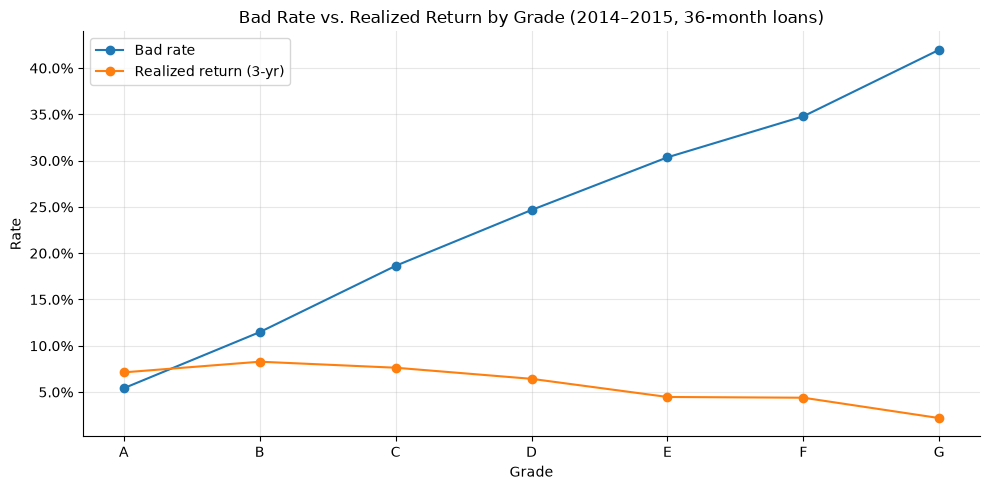

In [3]:
fig, ax = plt.subplots()
ax.plot(by_grade["grade"], by_grade["bad_rate"], marker="o", label="Bad rate")
ax.plot(by_grade["grade"], by_grade["realized_return"], marker="o", label="Realized return (3-yr)")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Bad Rate vs. Realized Return by Grade (2014–2015, 36-month loans)")
ax.set_xlabel("Grade")
ax.set_ylabel("Rate")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR / "bad_rate_vs_return_by_grade.png", dpi=150)
plt.show()

## 2. Segment view
Grades are grouped so segment-level ratios come straight from SQL (dollar-weighted returns) rather than being averaged by hand.

In [4]:
by_segment = con.sql("""
SELECT CASE
           WHEN grade = 'A'              THEN 'A'
           WHEN grade IN ('B', 'C')      THEN 'B-C'
           WHEN grade = 'D'              THEN 'D'
           WHEN grade IN ('E', 'F', 'G') THEN 'E-G'
       END                                                    AS grade_group,
       COUNT(*)                                               AS n_loans,
       ROUND(COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (), 4)        AS pct_loans,
       ROUND(AVG(bad_flag), 4)                                AS bad_rate,
       ROUND(SUM(total_pymnt) * 1.0 / SUM(funded_amnt) - 1, 4) AS realized_return
FROM cohort
GROUP BY grade_group
ORDER BY grade_group
""").df()
by_segment

,grade_group,n_loans,pct_loans,bad_rate,realized_return
0,A,105465,0.2366,0.0542,0.0713
1,B-C,266742,0.5984,0.1474,0.0799
2,D,53250,0.1195,0.2467,0.0643
3,E-G,20286,0.0455,0.3133,0.0441


In [5]:
seg = by_segment.set_index("grade_group")
print(f"E-G bad rate is {seg.loc['E-G', 'bad_rate'] / seg.loc['B-C', 'bad_rate']:.1f}x B-C")
print(f"B-C return is   {seg.loc['B-C', 'realized_return'] / seg.loc['E-G', 'realized_return']:.1f}x E-G")

E-G bad rate is 2.1x B-C
B-C return is   1.8x E-G


## 3. Recommendation

* **Don't simply raise rates on E–G.** Higher rates tend to attract borrowers with fewer alternatives (**adverse selection**) and raise repayment burden, which can push the bad rate higher still.
* **Tighten approval or cap exposure for E–G** (≈4.6% of loans) and shift volume toward **B–C**, the best risk-adjusted segment.

**Caveats:** returns are 3-year totals, not annualized, and are **before** servicing fees and funding costs; grade G has only 427 loans; `grade` and `int_rate` are outputs of Lending Club's existing model, so a new model should treat grade as a **benchmark**, not an input.